# Sentiment Analysis of IMDB Reviews from Scratch

Three ways to classify movie reviews as positive or negative, implemented in **Python and NumPy** with no machine-learning libraries:

1. **Class-conditional bigram language models.** One LM per class with Add-1 smoothing; a review goes to the class whose model gives it lower perplexity. The same models also generate text.
2. **Multinomial Naive Bayes** on the 2,000 most frequent unigrams and bigrams, using log-count ratios.
3. **NB-weighted logistic regression.** Feature counts are weighted by the Naive Bayes ratios, standardized, and fed to logistic regression trained with batch gradient descent.

Data: a balanced subset of the Stanford Large Movie Review Dataset (Maas et al., 2011), with 5,000 training and 1,000 test reviews drawn from the official splits.

| Test set (1,000 reviews) | Accuracy | F1 |
|---|---|---|
| Bigram language model | 84.70% | 0.8428 |
| Naive Bayes | 80.30% | 0.7967 |
| **NB-weighted logistic regression** | **85.90%** | **0.8627** |

**Contents.** Data setup and pre-processing · Part 1: Bigram language models (1.1–1.6) · Part 2: Naive Bayes (2.1–2.7) · Part 3: NB-weighted logistic regression (3.1–3.6) · Part 4: Model comparison and analysis.

The notebook runs top to bottom; the first code cell downloads the dataset (about 80 MB) if it isn't already present.

# Data setup

We use the Stanford Large Movie Review Dataset (aclImdb, Maas et al., 2011), which ships with an
official train/test split of 25,000 reviews each, balanced between positive and negative.
The archive is downloaded and extracted only if it is not already present.


In [1]:

from pathlib import Path
import urllib.request
import tarfile

url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
archive = Path("aclImdb_v1.tar.gz")
data_dir = Path("aclImdb")

if not (data_dir / "train" / "pos").exists():
    if not archive.exists():
        print("Downloading Stanford IMDB dataset...")
        urllib.request.urlretrieve(url, archive)

    print("Extracting dataset...")
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(path=".", filter="data")

print("Dataset ready:", data_dir.resolve())


Extracting dataset...
Dataset ready: /content/aclImdb


## Balanced subset

To keep training fast in pure NumPy, we sample a balanced subset:
- **Train:** 2,500 positive + 2,500 negative, drawn from the official `train/` split
- **Test:** 500 positive + 500 negative, drawn from the official `test/` split

Drawing train and test from separate splits guarantees no review appears in both.
Files are sorted before sampling and every draw uses a fixed seed, so the subset is identical on every run.
After combining the classes, reviews and labels are shuffled together so the data is not ordered by class.

In [2]:

import numpy as np
from pathlib import Path

DATA_DIR = Path("aclImdb")


def load_reviews(split, sentiment, count, seed=42):
    folder = DATA_DIR / split / sentiment
    files = sorted(folder.glob("*.txt"))

    if len(files) < count:
        raise ValueError(
            f"Expected at least {count} files in {folder}, "
            f"found {len(files)}"
        )

    rng = np.random.default_rng(seed)
    indices = rng.choice(len(files), size=count, replace=False)

    reviews = [
        files[i].read_text(encoding="utf-8", errors="replace")
        for i in indices
    ]

    label = 1 if sentiment == "pos" else 0
    labels = np.full(count, label, dtype=np.int64)

    return reviews, labels


# Training: 2,500 positive + 2,500 negative
x_train_pos, y_train_pos = load_reviews("train", "pos", 2500, 42)
x_train_neg, y_train_neg = load_reviews("train", "neg", 2500, 43)

# Testing: 500 positive + 500 negative
x_test_pos, y_test_pos = load_reviews("test", "pos", 500, 44)
x_test_neg, y_test_neg = load_reviews("test", "neg", 500, 45)


# Combine the classes
x_train = x_train_pos + x_train_neg
y_train = np.concatenate([y_train_pos, y_train_neg])

x_test = x_test_pos + x_test_neg
y_test = np.concatenate([y_test_pos, y_test_neg])


# Shuffle reviews and labels together
rng = np.random.default_rng(42)
train_idx = rng.permutation(len(y_train))
test_idx = rng.permutation(len(y_test))

x_train = [x_train[i] for i in train_idx]
y_train = y_train[train_idx]

x_test = [x_test[i] for i in test_idx]
y_test = y_test[test_idx]


# Verify the required sizes and balance
assert len(x_train) == 5000
assert len(x_test) == 1000
assert np.sum(y_train == 1) == 2500
assert np.sum(y_train == 0) == 2500
assert np.sum(y_test == 1) == 500
assert np.sum(y_test == 0) == 500

print("Training:", len(x_train))
print("Training labels [negative, positive]:", np.bincount(y_train))
print("Testing:", len(x_test))
print("Testing labels [negative, positive]:", np.bincount(y_test))


Training: 5000
Training labels [negative, positive]: [2500 2500]
Testing: 1000
Testing labels [negative, positive]: [500 500]


## First look at the raw text

Reading a few reviews shows the kinds of noise we need to handle: `<br />` line breaks,
mixed case, punctuation attached to words, contractions, and quotation marks.

In [3]:
for i in range(5):
    sentiment = "Positive" if y_train[i] == 1 else "Negative"

    print(f"\nReview {i + 1} — {sentiment}")
    print(x_train[i][:300])
    print("-" * 60)


Review 1 — Positive
As a big-time Prince fan of the last three to four years, I really can't believe I've only just got round to watching "Purple Rain". The brand new 2-disc anniversary Special Edition led me to buy it. Wow, I was really looking forward to watching it, but I wasn't prepared for just how electric it act
------------------------------------------------------------

Review 2 — Positive
A Brother's Promise is a wonderful family film. This is a biography of Dan Jansen, a champion Olympic speed skater. The movie depicts this athlete's life from a young age through full adulthood. The love and support of the family members is evident throughout. How Dan and the rest of his family hand
------------------------------------------------------------

Review 3 — Negative
Actress Patty Duke wrote an insightful, funny, rough-hewn book about her career as an actress, her crazy-quilt love-life, and her manic depressive episodes and suicide attempts which almost put her away for good. 

# Data pre-processing

## Inspecting the raw text

We count how often each kind of noise appears, so every cleaning step is justified by the data
rather than applied by default.

In [4]:

import re
import html

# Combine a sample of reviews for inspection only
sample = x_train[:500]
text = "\n".join(sample)

patterns = {
    "HTML break tags": r"<br\s*/?>",
    "Other HTML tags": r"<[^>]+>",
    "HTML entities": r"&(?:amp|lt|gt|quot|#\d+);",
    "URLs": r"https?://\S+|www\.\S+",
    "Repeated punctuation": r"[!?.,]{2,}",
    "Multiple whitespace": r"\s{2,}",
    "Digits": r"\d+",
    "Contractions": r"\b\w+'(?:t|s|re|ve|ll|d|m)\b",
    "Uppercase words": r"\b[A-Z]{2,}\b",
}

for name, pattern in patterns.items():
    matches = re.findall(pattern, text, flags=re.IGNORECASE if name == "Contractions" else 0)
    print(f"{name}: {len(matches)} matches")


HTML break tags: 2062 matches
Other HTML tags: 2062 matches
HTML entities: 0 matches
URLs: 3 matches
Repeated punctuation: 337 matches
Multiple whitespace: 4 matches
Digits: 732 matches
Contractions: 2273 matches
Uppercase words: 782 matches


## Cleaning pipeline


In [5]:
TAG_RE   = re.compile(r"<br\s*/?>|<[^>]+>")
URL_RE   = re.compile(r"https?://\S+|www\.\S+")
ELONG_RE = re.compile(r"([a-z])\1{2,}")       # sooooo -> soo (letters only, numbers untouched)
PUNCT_RE = re.compile(r"([!?])\1{2,}")       # !!!!! -> !!   ????? -> ??
KEEP_RE  = re.compile(r"([!?])")               # ! and ? become their own tokens
OTHER_RE = re.compile(r"[^a-z0-9'!?\s]")       # other punctuation -> space
QUOTE_RE = re.compile(r"(^|\s)'+|'+(?=\s|$)")  # quote marks, not apostrophes

def clean_text(text):
    text = html.unescape(text)
    text = text.lower()
    text = TAG_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = text.replace("’", "'").replace("‘", "'")
    text = ELONG_RE.sub(r"\1\1", text)
    text = PUNCT_RE.sub(r"\1\1", text)
    text = KEEP_RE.sub(r" \1 ", text)
    text = OTHER_RE.sub(" ", text)              # "movie...no" -> "movie   no"
    text = QUOTE_RE.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()

for i in range(2):
    print("RAW:  ", x_train[i][:250])
    print("CLEAN:", clean_text(x_train[i])[:250], "\n")

x_train_clean = [clean_text(r) for r in x_train]
x_test_clean  = [clean_text(r) for r in x_test]

RAW:   As a big-time Prince fan of the last three to four years, I really can't believe I've only just got round to watching "Purple Rain". The brand new 2-disc anniversary Special Edition led me to buy it. Wow, I was really looking forward to watching it, 
CLEAN: as a big time prince fan of the last three to four years i really can't believe i've only just got round to watching purple rain the brand new 2 disc anniversary special edition led me to buy it wow i was really looking forward to watching it but i w 

RAW:   A Brother's Promise is a wonderful family film. This is a biography of Dan Jansen, a champion Olympic speed skater. The movie depicts this athlete's life from a young age through full adulthood. The love and support of the family members is evident t
CLEAN: a brother's promise is a wonderful family film this is a biography of dan jansen a champion olympic speed skater the movie depicts this athlete's life from a young age through full adulthood the love and support of th

## Tokenizer

The tokenizer splits cleaned text into words with a single regular expression. A token is either:
- a run of letters/digits, optionally followed by an apostrophe part (`didn't`, `i've`), or
- a single `!` or `?`.

Every review is wrapped in `<s>` and `</s>`, so a sequence model can tell where a review starts and ends.

In [6]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[!?]")

def tokenize(text):
    return ["<s>"] + TOKEN_RE.findall(text) + ["</s>"]

# example
print(tokenize(clean_text("I didn't like it...<br /><br />SOOOO boring!! My Rating: 4/10")))
# ['<s>', 'i', "didn't", 'like', 'it', 'soo', 'boring', '!', '!', 'my', 'rating', '4', '10', '</s>']

train_tokens = [tokenize(t) for t in x_train_clean]
test_tokens  = [tokenize(t) for t in x_test_clean]

['<s>', 'i', "didn't", 'like', 'it', 'soo', 'boring', '!', '!', 'my', 'rating', '4', '10', '</s>']


In [7]:
# preview a few tokenized reviews from each set
for name, tokens, labels in [("Train", train_tokens, y_train), ("Test", test_tokens, y_test)]:
    print(f"===== {name}: {len(tokens)} reviews =====")
    for i in range(3):
        label = "Positive" if labels[i] == 1 else "Negative"
        seq = tokens[i]
        print(f"[{i}] {label}, {len(seq)} tokens")
        print("   ", seq[:20], "...", seq[-3:])
    print()

===== Train: 5000 reviews =====
[0] Positive, 320 tokens
    ['<s>', 'as', 'a', 'big', 'time', 'prince', 'fan', 'of', 'the', 'last', 'three', 'to', 'four', 'years', 'i', 'really', "can't", 'believe', "i've", 'only'] ... ['prince', 'groupie', '</s>']
[1] Positive, 142 tokens
    ['<s>', 'a', "brother's", 'promise', 'is', 'a', 'wonderful', 'family', 'film', 'this', 'is', 'a', 'biography', 'of', 'dan', 'jansen', 'a', 'champion', 'olympic', 'speed'] ... ['any', 'age', '</s>']
[2] Negative, 186 tokens
    ['<s>', 'actress', 'patty', 'duke', 'wrote', 'an', 'insightful', 'funny', 'rough', 'hewn', 'book', 'about', 'her', 'career', 'as', 'an', 'actress', 'her', 'crazy', 'quilt'] ... ['the', 'process', '</s>']

===== Test: 1000 reviews =====
[0] Positive, 153 tokens
    ['<s>', 'i', 'have', 'seen', 'over', '2000', 'studio', 'era', 'sound', 'films', 'including', 'lots', 'of', 'judy', 'garland', 'lena', 'horne', 'shirley', 'jones', 'and'] ... ['the', '20c', '</s>']
[1] Positive, 135 tokens
    ['<

# Part 1: Class-Conditional Bigram Language Models

## 1.1 Background: bigram language models

A **language model (LM)** assigns a probability to a sequence of words, e.g. "the movie was great" is likely, "great was movie the" is not. Equivalently, it predicts **which word comes next**.

### 1. Chain rule (exact, but impossible to estimate)

$$P(w_1, \dots, w_n) = \prod_{i=1}^{n} P(w_i \mid w_1, \dots, w_{i-1})$$

Every word depends on its **entire history**. Estimating $P(w_{150} \mid w_1 \dots w_{149})$ requires counting that exact 149-word history, which never appears in training ($0/0$). This is **data sparsity**.

### 2. Markov assumption → bigram model

Assume only the **previous word** matters:

$$P(w_i \mid w_1, \dots, w_{i-1}) \approx P(w_i \mid w_{i-1}) \quad\Rightarrow\quad P(w_1, \dots, w_n) \approx \prod_{i=1}^{n} P(w_i \mid w_{i-1})$$

*Example:* $P(\texttt{<s>}\text{ the movie was great }\texttt{</s>}) \approx P(\text{the}\mid\texttt{<s>})\,P(\text{movie}\mid\text{the})\,P(\text{was}\mid\text{movie})\,P(\text{great}\mid\text{was})\,P(\texttt{</s>}\mid\text{great})$

It ignores long-range context, but every factor can be estimated reliably.

### 3. Estimating by counting (MLE)

$$P(w_i \mid w_{i-1}) = \frac{C(w_{i-1}\,w_i)}{C(w_{i-1})}$$

$C(w_{i-1})$ counts how often $w_{i-1}$ is **followed by a word**, so the probabilities of all next words sum to 1. **Training is just counting.**

### 4. Add-1 (Laplace) smoothing

An unseen pair gets probability 0, and one zero makes the whole review's probability 0 ($\log 0 = -\infty$). Add 1 to every count:

$$P(w_i \mid w_{i-1}) = \frac{C(w_{i-1}\,w_i) + 1}{C(w_{i-1}) + V}$$

$V$ is the vocabulary size. The $+V$ keeps the probabilities summing to 1, since 1 was added for each of the $V$ possible next words. **Cost:** with a large $V$, a lot of probability moves to unseen pairs, so all probabilities become small and perplexities large.

### 5. Special tokens

- `<s>` / `</s>`: learn how reviews **start** and **end**; `</s>` also tells the generator when to stop.
- `<UNK>`: test words never seen in training are replaced with `<UNK>`, so every word has a probability.

### 6. Class-conditional LMs

We train **one LM per class**: the positive LM estimates $P(\text{text} \mid \text{pos})$ from positive reviews only, the negative LM $P(\text{text} \mid \text{neg})$ from negative reviews only. Both share the **same vocabulary and $V$**, so their probabilities are directly comparable.

In [8]:
# Class-conditional LMs need separate training data per class
# Each LM sees ONLY its own class, so it learns how that class "talks"
# Labels: 1 = positive, 0 = negative
pos_reviews = [tokens for tokens, label in zip(train_tokens, y_train) if label == 1]
neg_reviews = [tokens for tokens, label in zip(train_tokens, y_train) if label == 0]

print("Positive reviews:", len(pos_reviews))   # expect 2500
print("Negative reviews:", len(neg_reviews))   # expect 2500

Positive reviews: 2500
Negative reviews: 2500


## 1.2 Shared vocabulary

The vocabulary is every distinct training word (a set drops repeats automatically). `<s>` is removed because it is never predicted as a next word; `<UNK>` is added as a slot for unknown test words. $V$ is the $+V$ in Add-1 smoothing. Both models use the **same** $V$, so their probabilities are comparable.

In [9]:
# ONE vocabulary for BOTH models
# Why shared? Add-1 divides by (C(prev) + V)
# If the two models had different V
# their probabilities would be on different scales and comparing perplexities would be unfair.
vocab = {tok for review in train_tokens for tok in review}   # set -> each word counted once

vocab.discard("<s>")   # <s> is only ever a context (prev) - never predicted as a next word
vocab.add("<UNK>")     # one slot for test words never seen in training
V = len(vocab)         # this is the +V in the Add-1 denominator

print("Vocabulary size V:", V)

Vocabulary size V: 41300


## 1.3 Counting bigrams and contexts for each class

Each LM stores two counters, which are the two parts of the formula $P(w \mid \text{prev}) = \dfrac{C(\text{prev}\,w) + 1}{C(\text{prev}) + V}$:

- `bigram_counts[(prev, word)]` → $C(\text{prev}\,w)$, the **numerator**
- `context_counts[prev]` → $C(\text{prev})$, how often `prev` was followed by a word, the **denominator**

`zip(tokens[:-1], tokens[1:])` pairs each token with the one after it:

```
tokens       = ['<s>', 'great', 'movie', '</s>']
tokens[:-1]  = ['<s>', 'great', 'movie']
tokens[1:]   = ['great', 'movie', '</s>']
pairs        = (<s>, great)  (great, movie)  (movie, </s>)
```

Both counters are updated in the same loop, so each context count always equals the total of its pair counts (and `</s>` is never a context, since nothing follows it). The function is called **twice**: once with the positive reviews and once with the negative reviews, giving two independent models.

In [10]:
from collections import Counter

def train_bigram_lm(reviews, V):
    # Training a bigram LM is just counting (Maximum Likelihood Estimation)
    bigram_counts = Counter()    # C(prev, word): numerator of P(word | prev)
    context_counts = Counter()   # C(prev): how often prev was followed by any word -> denominator

    for tokens in reviews:
        # zip(tokens[:-1], tokens[1:]) gives every neighbouring pair:
        # ['<s>','great','movie','</s>'] -> (<s>,great) (great,movie) (movie,</s>)
        for prev, word in zip(tokens[:-1], tokens[1:]):
            bigram_counts[(prev, word)] += 1
            context_counts[prev] += 1     # updated in the same loop, so it always equals
                                          # the sum of that prev's bigram counts
    # </s> is never a context because nothing comes after it
    return {"bigrams": bigram_counts, "contexts": context_counts, "V": V}

# Same function, called twice on different data --> two independent models
pos_lm = train_bigram_lm(pos_reviews, V)
neg_lm = train_bigram_lm(neg_reviews, V)

print("Distinct positive bigrams:", len(pos_lm["bigrams"]))
print("Distinct negative bigrams:", len(neg_lm["bigrams"]))

Distinct positive bigrams: 262695
Distinct negative bigrams: 246078


### Add-1 smoothed probability

This function is the Add-1 formula (section 1.1, item 4) written as code:

$$P(\text{word} \mid \text{prev}) = \frac{C(\text{prev}\ \text{word}) + 1}{C(\text{prev}) + V}$$

- A pair never seen gets $1 / (C(\text{prev}) + V)$: small, but never zero.
- If `prev` itself was never seen as a context, the result is $1/V$ for every word: a uniform guess, because the model knows nothing about what follows it.

In [11]:
def bigram_prob(lm, prev, word):
    # Add-1 (Laplace) smoothing: P(word | prev) = (C(prev, word) + 1) / (C(prev) + V)
    # +1 in the numerator: an unseen pair gets a small probability instead of 0,
    #   because a single 0 would make the whole review's probability 0 (log 0 = -inf)
    # +V in the denominator: we added 1 for each of the V possible next words,
    #   so we add V below to keep the probabilities summing to 1


    return (lm["bigrams"][(prev, word)] + 1) / (lm["contexts"][prev] + lm["V"])

## 1.4 Log-likelihood and perplexity

### Log-likelihood (LL)

A review's probability is a product of many small probabilities. For a 200-word review that is about $0.01^{200} = 10^{-400}$, too small for a computer, so it becomes 0 (**underflow**). Taking logs turns the product into a sum:

$$\text{LL} = \sum_{i=1}^{N} \log P(w_i \mid w_{i-1})$$

LL is always negative. **Closer to 0 = more likely.** $N$ is the number of bigrams, `len(tokens) - 1`.

### Perplexity (PP)

Longer reviews add more negative terms, so their LL is always lower. Perplexity averages per word so reviews of any length can be compared:

$$\text{PP} = \exp\left(-\frac{\text{LL}}{N}\right)$$

PP is roughly the number of words the model was "choosing between" at each step. **Lower PP = less surprised = better fit.**

### Unknown words

Test words not in the vocabulary are replaced with `<UNK>` before scoring, e.g. `['<s>', 'amazng', 'film', '</s>']` → `['<s>', '<UNK>', 'film', '</s>']`.

### Worked example

`<s> great movie </s>` ($N = 3$), using these illustrative log-probabilities:

| Bigram | log P (positive) | log P (negative) |
|---|---|---|
| `<s>` → great | −1.099 | −2.197 |
| great → movie | −1.504 | −1.946 |
| movie → `</s>` | −1.386 | −1.386 |
| **LL** | **−3.989** | **−5.529** |
| **PP** $= e^{-\text{LL}/3}$ | **3.78** | **6.32** |

The positive LM is less surprised, as expected.

### Functions

- `replace_unknown`: unknown words → `<UNK>`
- `log_likelihood_and_perplexity`: LL and PP of one review under one LM
- `score_document`: takes raw text or tokens and returns LL and PP under **both** LMs

In [12]:
import math

def replace_unknown(tokens, vocab):
    # Test words never seen in training are mapped to <UNK> so every word has a probability
    # tokens[0] is <s>, which we removed from vocab on purpose, so we keep it as-is
    return [tokens[0]] + [tok if tok in vocab else "<UNK>" for tok in tokens[1:]]


def log_likelihood_and_perplexity(tokens, lm, vocab):
    tokens = replace_unknown(tokens, vocab)

    # Log-likelihood: sum of log probabilities instead of a product of probabilities
    # A product of hundreds of small numbers underflows to 0 on a computer; a sum of logs doesn't
    log_likelihood = 0.0
    for prev, word in zip(tokens[:-1], tokens[1:]):
        log_likelihood += math.log(bigram_prob(lm, prev, word))

    # N = number of predictions made (one per bigram), including predicting </s>
    n = len(tokens) - 1

    # Perplexity = exp(-LL / N): the per-word average, so long and short reviews are comparable
    # Lower perplexity = the model is less "surprised" = the text fits that model better
    perplexity = math.exp(-log_likelihood / n)
    return log_likelihood, perplexity


def score_document(document, pos_lm, neg_lm, vocab):
    # Accepts raw text (cleans + tokenizes it) or an already tokenized list
    if isinstance(document, str):
        tokens = tokenize(clean_text(document))
    else:
        tokens = document

    # Score the SAME tokens under BOTH models, so the two results are directly comparable
    pos_ll, pos_pp = log_likelihood_and_perplexity(tokens, pos_lm, vocab)
    neg_ll, neg_pp = log_likelihood_and_perplexity(tokens, neg_lm, vocab)

    return {"pos_ll": pos_ll, "pos_pp": pos_pp,
            "neg_ll": neg_ll, "neg_pp": neg_pp}

### Scoring real documents

We score one real test review and two sentences of our own under both models. What matters is **which** perplexity is lower, not how large they are: Add-1 smoothing with a vocabulary of tens of thousands of words makes every perplexity large for both models alike.

For a long real review the two perplexities are usually close, because most of its words ("the", "of", plot description) are neutral and both models predict them about equally well. Short, sentiment-heavy sentences show a much bigger gap.

In [13]:

result = score_document(test_tokens[0], pos_lm, neg_lm, vocab)
true_label = "Positive" if y_test[0] == 1 else "Negative"
print(f"Test review 0 (true label: {true_label})")
print(f"  Positive LM: log-likelihood = {result['pos_ll']:.2f}, perplexity = {result['pos_pp']:.2f}")
print(f"  Negative LM: log-likelihood = {result['neg_ll']:.2f}, perplexity = {result['neg_pp']:.2f}")


examples = [
    "This movie was absolutely wonderful, I loved every minute of it!",
    "What a waste of time. The worst film I have ever seen.",
]
for text in examples:
    res = score_document(text, pos_lm, neg_lm, vocab)
    print(f"\n{text}")
    print(f"  Positive LM perplexity: {res['pos_pp']:.2f}")
    print(f"  Negative LM perplexity: {res['neg_pp']:.2f}")

Test review 0 (true label: Positive)
  Positive LM: log-likelihood = -1380.14, perplexity = 8776.80
  Negative LM: log-likelihood = -1381.91, perplexity = 8879.43

This movie was absolutely wonderful, I loved every minute of it!
  Positive LM perplexity: 1169.86
  Negative LM perplexity: 1520.33

What a waste of time. The worst film I have ever seen.
  Positive LM perplexity: 1577.65
  Negative LM perplexity: 500.35


## 1.5 Using the language models as a classifier

### Generative classification with Bayes' rule

Each LM models how text of its class is **generated**, $P(d \mid c)$. To classify a document $d$ we want the most probable class given the text. Bayes' rule connects the two:

$$P(c \mid d) = \frac{P(d \mid c)\, P(c)}{P(d)} \quad\Longrightarrow\quad \hat{y} = \arg\max_{c} \; P(d \mid c)\, P(c)$$

($P(d)$ is the same for both classes, so it does not affect the choice.)

Our training classes are balanced (2,500 / 2,500), so $P(\text{pos}) = P(\text{neg}) = 0.5$ and the prior also drops out:

$$\hat{y} = \arg\max_{c} \; P(d \mid c)$$

### Why "lower perplexity" is the same rule

Both models score the **same** document, so $N$ is the same for both. Since $\text{PP} = \exp(-\text{LL}/N)$ and $\exp$ is increasing:

$$\text{PP}_{\text{pos}} < \text{PP}_{\text{neg}} \iff \text{LL}_{\text{pos}} > \text{LL}_{\text{neg}} \iff P(d \mid \text{pos}) > P(d \mid \text{neg})$$

So choosing the lower perplexity is exactly choosing the class whose model makes the document most likely.

**Decision rule:** predict positive (`1`) if $\text{PP}_{\text{pos}} < \text{PP}_{\text{neg}}$, otherwise negative (`0`).

### Evaluation metrics

With positive as the target class:

| | Truly positive | Truly negative |
|---|---|---|
| **Predicted positive** | TP (true positive) | FP (false positive) |
| **Predicted negative** | FN (false negative) | TN (true negative) |

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN}$$

$$F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Precision:** of the reviews we called positive, how many really were.
- **Recall:** of the truly positive reviews, how many we found.
- **F1:** the harmonic mean of the two; it is high only when both are high.


In [14]:
def accuracy(y_true, y_pred):
    # fraction of reviews predicted correctly
    return np.mean(y_true == y_pred)

def f1_score(y_true, y_pred, positive=1):
    # F1 for the positive class. Returns (f1, precision, recall);
    # the whole notebook uses this one definition
    tp = np.sum((y_pred == positive) & (y_true == positive))   # predicted pos, really pos
    fp = np.sum((y_pred == positive) & (y_true != positive))   # predicted pos, really neg
    fn = np.sum((y_pred != positive) & (y_true == positive))   # predicted neg, really pos
    precision = tp / (tp + fp) if tp + fp else 0.0   # of predicted positives, how many are right
    recall    = tp / (tp + fn) if tp + fn else 0.0   # of real positives, how many we found
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return f1, precision, recall

def predict_lm(token_lists, pos_lm, neg_lm, vocab):
    # Generative classification: pick the class whose LM makes the review most likely
    # Lower perplexity <=> higher log-likelihood <=> higher P(review | class),
    # because both models score the same review (same N) and exp is increasing
    # Classes are balanced (2500/2500), so the prior P(class) is equal and drops out
    preds = []
    for tokens in token_lists:
        _, pos_pp = log_likelihood_and_perplexity(tokens, pos_lm, vocab)
        _, neg_pp = log_likelihood_and_perplexity(tokens, neg_lm, vocab)
        preds.append(1 if pos_pp < neg_pp else 0)
    return np.array(preds)


y_pred_lm = predict_lm(test_tokens, pos_lm, neg_lm, vocab)

lm_accuracy = accuracy(y_test, y_pred_lm)
lm_f1, lm_precision, lm_recall = f1_score(y_test, y_pred_lm)

# Confusion matrix counts (same layout as the Naive Bayes section)
tn = np.sum((y_pred_lm == 0) & (y_test == 0)); fp = np.sum((y_pred_lm == 1) & (y_test == 0))
fn = np.sum((y_pred_lm == 0) & (y_test == 1)); tp = np.sum((y_pred_lm == 1) & (y_test == 1))

print(f"Bigram LM — Accuracy: {lm_accuracy:.4f} | F1: {lm_f1:.4f} "
      f"(precision {lm_precision:.4f}, recall {lm_recall:.4f})")
print("Predictions [negative, positive]:", np.bincount(y_pred_lm, minlength=2))
print("Confusion matrix [rows = true neg/pos, cols = predicted neg/pos]:")
print(np.array([[tn, fp], [fn, tp]]))

Bigram LM — Accuracy: 0.8470 | F1: 0.8428 (precision 0.8668, recall 0.8200)
Predictions [negative, positive]: [527 473]
Confusion matrix [rows = true neg/pos, cols = predicted neg/pos]:
[[437  63]
 [ 90 410]]


## 1.6 Next-word prediction

Starting from a prompt, the model repeatedly predicts the next word from the **last word only** (the bigram assumption), appends it, and continues until it produces `</s>` or reaches `max_len`.

- **Greedy** always picks the most probable word. With one word of memory it soon loops (e.g. "film is a great film is a great…").
- **Top-k sampling** picks randomly among the k most probable words, giving more varied text. It avoids the thousands of unseen words that Add-1 gives small probabilities to.

`build_next_word_table` reorganises the bigram counts by first word, so finding all words that followed a word is one lookup.

In [15]:
from collections import defaultdict

def build_next_word_table(lm):
    # Reorganise the bigram counts by first word: table[prev] = {next_word: count}
    # so "which words followed prev?" is one lookup instead of scanning all 250k bigrams
    table = defaultdict(Counter)
    for (prev, word), count in lm["bigrams"].items():
        table[prev][word] = count
    return table

pos_next = build_next_word_table(pos_lm)
neg_next = build_next_word_table(neg_lm)

# Words the generator may output (<UNK> is excluded: it isn't a real word)
vocab_list = sorted(w for w in vocab if w != "<UNK>")
word_index = {w: i for i, w in enumerate(vocab_list)}   # word -> position in the probability vector


def next_word_probs(lm, next_table, prev):
    # Add-1 smoothed P(w | prev) for every candidate word, as one NumPy vector.
    counts = np.ones(len(vocab_list))              # the +1 for every word (Add-1)
    for word, c in next_table[prev].items():
        if word in word_index:
            counts[word_index[word]] += c          # add the real bigram counts
    # Normalise so the vector sums to 1 over the words we can output (<UNK> excluded)
    # This is the same as dividing by C(prev) + V, minus the <UNK> slot, so the
    # ranking of words is identical to the Add-1 formula
    return counts / counts.sum()


def generate(prompt, lm, next_table, max_len=20, method="greedy", k=10, seed=None):
    rng = np.random.default_rng(seed)              # fixed seed -> reproducible top-k output
    tokens = tokenize(clean_text(prompt))[:-1]     # keep <s>, drop the final </s> so we can continue

    new_words = 0
    while new_words < max_len:                     # stop condition 1: max length reached
        # Bigram assumption: only the LAST word is used as context
        probs = next_word_probs(lm, next_table, tokens[-1])

        if method == "greedy":
            # Always take the most probable word. With one word of memory it gets stuck
            # in loops like "is a great film is a great film "
            idx = int(np.argmax(probs))
        else:
            # Top-k sampling: pick randomly among the k most likely words
            # Gives more varied text, and never picks the thousands of unseen words
            # that only have the tiny Add-1 probability
            top = np.argsort(probs)[-k:]
            p = probs[top] / probs[top].sum()      # renormalise the k probabilities to sum to 1
            idx = int(rng.choice(top, p=p))

        word = vocab_list[idx]
        if word == "</s>":                         # stop condition 2: model predicts end of review
            break
        tokens.append(word)
        new_words += 1

    return " ".join(tokens[1:])                    # drop <s> for printing

In [16]:
# Same prompts under both LMs: the positive model drifts towards "great film",
# the negative one towards neutral or negative phrases -> the two LMs really learned different language
prompts = ["the movie was", "i think this film", "the acting"]

for i, prompt in enumerate(prompts):
    print(f"Prompt: {prompt!r}")
    print("  Positive (greedy):", generate(prompt, pos_lm, pos_next, max_len=15))
    print("  Negative (greedy):", generate(prompt, neg_lm, neg_next, max_len=15))
    print("  Positive (top-10):", generate(prompt, pos_lm, pos_next, max_len=15, method="topk", seed=i))
    print("  Negative (top-10):", generate(prompt, neg_lm, neg_next, max_len=15, method="topk", seed=i))
    print()

Prompt: 'the movie was'
  Positive (greedy): the movie was a great film is a great film is a great film is a great film
  Negative (greedy): the movie was a movie is a movie is a movie is a movie is a movie is
  Positive (top-10): the movie was the most notably about the film and the story is a young woman of the
  Negative (top-10): the movie was the end but they are the film is the movie is in the most of

Prompt: 'i think this film'
  Positive (greedy): i think this film is a great film is a great film is a great film is a great
  Negative (greedy): i think this film is a movie is a movie is a movie is a movie is a movie
  Positive (top-10): i think this film that the same time in a lot of the characters and i am not be
  Negative (top-10): i think this film and the same time on a lot of the most of the only one thing

Prompt: 'the acting'
  Positive (greedy): the acting is a great film is a great film is a great film is a great
  Negative (greedy): the acting is a movie is a movie 

# Part 2: Naive Bayes

## 2.1 Background: multinomial Naive Bayes

The bigram LMs scored a review word by word in order. Naive Bayes instead treats a review as a **bag of features** (unigrams and bigrams), where order is ignored and only counts matter.

Each review $d$ becomes a count vector $x$, where $x_j$ is how often feature $f_j$ appears. The **naive assumption** is that features are independent given the class:

$$P(d \mid c) \propto \prod_{j} P(f_j \mid c)^{\,x_j}$$

This assumption is clearly false: "waste" and "waste of" are strongly correlated. Even so, it works well for sentiment, because the decision depends mostly on *which* words appear.

## 2.2 Feature vocabulary (unigrams + bigrams)

Each review is turned into a list of n-grams:

- **Unigrams**: every token except `<s>` and `</s>`. These appear in every review, so they carry no information about sentiment.
- **Bigrams**: every neighbouring pair, *including* the boundary tokens. This lets patterns like `<s> this` or `! </s>` capture how reviews start and end.

Bigrams let the model see short phrases that single words miss, such as **"not good"**, **"waste of"** and **"the worst"**.

Counts are taken from the **training set only**. We keep the **2,000 most frequent** n-grams as features and drop everything else. This keeps the feature matrix small enough for pure NumPy.

In [17]:
from collections import Counter

SPECIALS = {"<s>", "</s>"}
VOCAB_SIZE = 2000

def extract_ngrams(tokens):
    unigrams = [t for t in tokens if t not in SPECIALS]           # <s>,</s> appear in every review -> no information
    bigrams  = [f"{a} {b}" for a, b in zip(tokens, tokens[1:])]   # e.g. "not good", "<s> this", "! </s>"
    return unigrams + bigrams

# count unigrams and bigrams together, on the training set only
ngram_counts = Counter()
for seq in train_tokens:
    ngram_counts.update(extract_ngrams(seq))

features    = [g for g, _ in ngram_counts.most_common(VOCAB_SIZE)] # returns the 2,000 most frequent (ngram, count) pairs
feature2idx = {g: i for i, g in enumerate(features)}               # n-gram -> column index in X

# Bigram features contain a space, unigrams don't
n_bigrams = sum(" " in f for f in features)
print(f"Distinct n-grams in train: {len(ngram_counts):,}")
print(f"Vocabulary: {len(features)} features ({len(features) - n_bigrams} unigrams, {n_bigrams} bigrams)")
print("Top 20:", features[:20])

Distinct n-grams in train: 482,780
Vocabulary: 2000 features (1161 unigrams, 839 bigrams)
Top 20: ['the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this', 'that', 'as', 'was', 'with', 'for', 'movie', 'but', 'of the', 'film', 'on']


## 2.3 Count vectors

Each review becomes a row of the matrix $X$:

$$X_{i,j} = \text{count of feature } f_j \text{ in review } i$$

N-grams outside the 2,000-feature vocabulary are skipped: they have no column in $X$ and no weight $r_j$. Keeping only the most frequent n-grams keeps the matrix small and avoids unreliable estimates from rare n-grams. The cost is that much of each review's text is ignored. The result is $X_\text{train} \in \mathbb{R}^{5000 \times 2000}$ and $X_\text{test} \in \mathbb{R}^{1000 \times 2000}$.


In [18]:
def vectorize(token_lists):
    # One row per review, one column per feature; X[i, j] = count of feature j in review i
    X = np.zeros((len(token_lists), VOCAB_SIZE), dtype=np.float32)
    for i, seq in enumerate(token_lists):
        for g in extract_ngrams(seq):
            j = feature2idx.get(g)          # None if the n-gram is not one of the 2,000 features
            if j is not None:               # out-of-vocabulary -> skip
                X[i, j] += 1
    return X

X_train = vectorize(train_tokens)
X_test  = vectorize(test_tokens)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
# Average number of feature occurrences per review (how much of each review the model "sees")
print("Avg vocabulary hits per review:", X_train.sum(axis=1).mean().round(1))

X_train: (5000, 2000) | X_test: (1000, 2000)
Avg vocabulary hits per review: 235.9


## 2.4 Class-conditional feature probabilities

We sum the count columns over the reviews of each class, then apply **Add-1 (Laplace) smoothing**:

$$P(f_j \mid c) = \frac{\text{count}(f_j, c) + 1}{\sum_k \text{count}(f_k, c) + |V|}, \qquad |V| = 2000$$

This is the same idea as in the bigram LM. Without the $+1$, a feature never seen in one class would get probability 0, which gives $\log 0 = -\infty$. The $+|V|$ keeps each distribution summing to 1.

In [19]:
# Total count of each feature across all reviews of one class
pos_counts = X_train[y_train == 1].sum(axis=0)     # count of each feature in positive reviews
neg_counts = X_train[y_train == 0].sum(axis=0)     # count of each feature in negative reviews

# Laplace (add-1): P(f|c) = (count(f,c) + 1) / (total count in c + |V|)
p_pos = (pos_counts + 1) / (pos_counts.sum() + VOCAB_SIZE)
p_neg = (neg_counts + 1) / (neg_counts.sum() + VOCAB_SIZE)

## 2.5 Log-count ratios

For each feature we compute

$$r_j = \log \frac{P(f_j \mid \text{pos})}{P(f_j \mid \text{neg})}$$

- $r_j > 0$: the feature is more typical of positive reviews.
- $r_j < 0$: the feature is more typical of negative reviews.
- $r_j \approx 0$: the feature is neutral (e.g. "the", "of").

The vector $r$ is the whole trained model. Sorting it shows what the classifier has learned. Most top features are real sentiment words (*superb*, *waste of*, *poorly*). A few reflect **topic bias** in the data: "bond" (James Bond films) leans positive and "zombies" leans negative, even though neither word expresses an opinion.

In [20]:
r = np.log(p_pos / p_neg)          # r_j > 0 -> leans positive, r_j < 0 -> leans negative

order = np.argsort(r)              # feature indices sorted from most negative to most positive r
print("Most POSITIVE features:")
for j in order[::-1][:15]:
    print(f"  {features[j]:<20} r = {r[j]:+.3f}")
print("\nMost NEGATIVE features:")
for j in order[:15]:
    print(f"  {features[j]:<20} r = {r[j]:+.3f}")

Most POSITIVE features:
  bond                 r = +1.787
  incredible           r = +1.656
  superb               r = +1.516
  a wonderful          r = +1.515
  oscar                r = +1.484
  amazing              r = +1.414
  excellent            r = +1.382
  brilliant            r = +1.382
  wonderful            r = +1.371
  perfectly            r = +1.362
  the greatest         r = +1.354
  powerful             r = +1.351
  fantastic            r = +1.350
  my favorite          r = +1.304
  perfect              r = +1.288

Most NEGATIVE features:
  waste of             r = -2.911
  waste                r = -2.622
  the worst            r = -2.327
  worst                r = -2.286
  so bad               r = -2.284
  pointless            r = -2.277
  poorly               r = -2.244
  awful                r = -2.146
  zombies              r = -2.025
  mess                 r = -2.015
  your time            r = -1.940
  dumb                 r = -1.817
  worse                r = -1.754

## 2.6 Classification rule

Taking the log of Bayes' rule and comparing the two classes gives a **linear score**:

$$\text{score}(d) = \log\frac{P(\text{pos})}{P(\text{neg})} + \sum_j x_j \, r_j$$

Predict **positive (1)** if $\text{score}(d) > 0$, otherwise **negative (0)**.

The training set is balanced (2,500 / 2,500), so the log prior is $0$ and only the features decide.

The rule is implemented two ways:
- `predict_document` loops over the n-grams of one review and adds up their $r_j$.
- `predict` computes all scores at once as a matrix product, $X r + \log\text{prior}$.

Because the score is just $X r$, Naive Bayes is a linear classifier with fixed weights $r$. Part 3 builds on this: it uses $r$ to weight the features and then *learns* the weights with Logistic Regression.

In [21]:
log_prior = np.log(np.mean(y_train == 1) / np.mean(y_train == 0))   # log P(pos)/P(neg) = 0 for a balanced set
print("Log prior ratio:", log_prior)

def predict_document(tokens):
    # Score one review by looping over its n-grams: log_prior + sum of r_j for each feature hit
    score = log_prior
    for g in extract_ngrams(tokens):
        j = feature2idx.get(g)
        if j is not None:
            score += r[j]
    return int(score > 0), score

def predict(X):
    scores = X @ r + log_prior
    return (scores > 0).astype(np.int64), scores

y_pred, test_scores = predict(X_test)

print("Example:", predict_document(test_tokens[0]), "| true label:", y_test[0])

Log prior ratio: 0.0
Example: (1, np.float64(3.572634750045836)) | true label: 1


In [22]:
acc = accuracy(y_test, y_pred)
f1, prec, rec = f1_score(y_test, y_pred)

tn = np.sum((y_pred == 0) & (y_test == 0)); fp = np.sum((y_pred == 1) & (y_test == 0))
fn = np.sum((y_pred == 0) & (y_test == 1)); tp = np.sum((y_pred == 1) & (y_test == 1))

print(f"Baseline Naive Bayes — Accuracy: {acc:.4f} | F1: {f1:.4f} (precision {prec:.4f}, recall {rec:.4f})")
print("Confusion matrix [rows = true neg/pos, cols = predicted neg/pos]:")
print(np.array([[tn, fp], [fn, tp]]))
print("Train accuracy:", accuracy(y_train, predict(X_train)[0]).round(4))

Baseline Naive Bayes — Accuracy: 0.8030 | F1: 0.7967 (precision 0.8230, recall 0.7720)
Confusion matrix [rows = true neg/pos, cols = predicted neg/pos]:
[[417  83]
 [114 386]]
Train accuracy: 0.8128


## 2.7 Results

| Model | Accuracy | F1 | Precision | Recall |
|---|---|---|---|---|
| Bigram LM | 0.8470 | 0.8428 | 0.8668 | 0.8200 |
| **Naive Bayes** | **0.8030** | **0.7967** | **0.8230** | **0.7720** |

- **Recall is lower than precision.** In the confusion matrix, 114 positive reviews were labelled negative and 83 negative reviews were labelled positive, so the model leans towards predicting negative.
- **No overfitting.** Train accuracy (81.3%) is close to test accuracy (80.3%), so the model is limited by its features, not by memorising the training data.
- **Why it trails the bigram LM:** the 2,000-feature vocabulary covers only a small slice of the 482,780 distinct n-grams in the training set. On average a review hits about 236 features and the rest of its words are ignored. In contrast, the LM uses its whole vocabulary of 41,300 entries. The independence assumption also double-counts overlapping features such as "waste" and "waste of".

# Part 3: NB-Weighted Logistic Regression

## 3.1 NB-weighted features

The goal is a binary sentiment classifier built on the Naive Bayes features from Part 2. The labels are **0 = negative** and **1 = positive**.

We reuse the feature-count matrices X_train and X_test from Part 2, each containing 2,000 unigram and bigram features. We also reuse the Naive Bayes log-ratio vector r and the corresponding labels y_train and y_test. These values provide the inputs needed to train and evaluate our Logistic Regression classifier.

We multiply the count of each unigram/bigram feature by its Naive Bayes log-ratio:

$$
X_{i,j}^{\mathrm{weighted}} = \mathrm{count}(f_j \text{ in review } i)\,r_j
$$

where $r_j$ is positive for features associated more strongly with positive reviews and negative for features associated more strongly with negative reviews.

`X_train_weighted` and `X_test_weighted` are computed with NumPy broadcasting. Test labels are never used to construct the features.


In [23]:
# X_train and X_test contain the counts of 2,000 features per review.
# r contains the Naive Bayes log-ratio for each feature.

# Multiply every feature count by its corresponding sentiment log-ratio.
# NumPy broadcasting applies r[j] to column j for every review.
# The test set uses the SAME r calculated from training data.

X_train_weighted = (X_train * r).astype(np.float32)
X_test_weighted  = (X_test * r).astype(np.float32)

print('NB-weighted training shape:', X_train_weighted.shape)
print('NB-weighted testing shape: ', X_test_weighted.shape)
assert X_train_weighted.shape == (5000, 2000)
assert X_test_weighted.shape == (1000, 2000)

NB-weighted training shape: (5000, 2000)
NB-weighted testing shape:  (1000, 2000)


## 3.2 Z-score standardization and bias

**Why standardize?** Different feature columns can have very different scales. Z-score normalization puts them on a more comparable scale so gradient descent can optimize the weights more effectively.

For each feature column $j$:

$$
Z_{i,j} = \frac{X_{i,j}^{\mathrm{weighted}} - \mu_j}{\sigma_j}
$$

- $\mu_j$: mean of feature $j$ **computed on training data only**.
- $\sigma_j$: standard deviation of feature $j$ **computed on training data only**.
- If $\sigma_j = 0$, replace the denominator with **1** to avoid division by zero.

**No data leakage:** the mean and standard deviation are computed on the training set only, and the *same values* are applied to validation and test reviews.

**Bias column:** a column of ones is prepended so that the model can learn the intercept $w_0$. This changes the matrix width from **2,000 to 2,001** features.

The functions in the next code cell perform the training-only fit and the reusable transformation.


In [24]:
def fit_standardizer(X):
    """Learn column-wise scaling parameters from training features only."""

    # axis=0 means calculate one mean for each FEATURE column,
    # across all training reviews
    mean = X.mean(axis=0)
    # measures the variation of each feature.
    std = X.std(axis=0)
    std = np.where(std == 0, 1.0, std)  # constant columns: divide by 1 instead of 0
    return mean, std


def transform_with_bias(X, mean, std):
    """Use fixed training parameters to standardize and add a bias column."""
    # Z-score = (feature value - training mean) / training std.
    # Reuse training statistics when transforming validation/test data.
    X_scaled = (X - mean) / std
    # bias column
    ones = np.ones((X.shape[0], 1), dtype=np.float32)
    # Place bias first: 2,000 features become 2,001 columns
    return np.hstack((ones, X_scaled)).astype(np.float32)

## 3.3 Logistic regression from scratch

Logistic Regression predicts the probability that each IMDB review is **positive**.

### 1. Linear score and sigmoid

First, combine all features with the learnable weight vector $w$ (including the bias weight):

$$
z = Xw
$$

Then convert each score to a probability between 0 and 1:

$$
p = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

Prediction rule: **positive (1)** if $p \geq 0.5$; otherwise **negative (0)**.

### 2. Binary Cross-Entropy (BCE) loss

For $N$ reviews, the loss is:

$$
L = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right]
$$

The implementation uses `np.logaddexp(0, z) - y*z`, which computes the same loss more safely from the raw scores.

### 3. Gradient descent

For each epoch, calculate the gradient and update the weights:

$$
\nabla_w L = \frac{X^T(p-y)}{N}
$$

$$
w \leftarrow w - \alpha\,\nabla_w L
$$

Here $\alpha$ is the **learning rate**, and an **epoch** is one complete pass through the training reviews. We print and store the loss during training, then plot it later.

The next cell implements `sigmoid`, BCE loss, `fit`, `predict_proba`, and `predict` in a `LogisticRegression` class.


In [25]:
class LogisticRegression:
    """Binary Logistic Regression trained with NumPy batch gradient descent."""

    # Constructor: stores training settings and initializes model state.
    # learning_rate controls how far each gradient update moves.
    # epochs controls how many training iterations are performed.
    # loss_history stores BCE values for plotting after training.

    def __init__(self, learning_rate=0.05, epochs=300, print_every=25):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.print_every = print_every
        self.weights = None
        self.loss_history = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -50.0, 50.0)  # protect exp() from overflow
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def bce_loss(y, logits):
        # Binary cross-entropy evaluated directly from logits
        return float(np.mean(np.logaddexp(0.0, logits) - y * logits))
        # np.logaddexp computes BCE from logits in a stable way,
        # avoiding log(0) and overflow problems.

    def fit(self, X, y):
        y = np.asarray(y, dtype=np.float32)   # Convert true sentiment labels to float for calculations.
        self.weights = np.zeros(X.shape[1], dtype=np.float32)
        self.loss_history = []     # Clear any loss values left from previous training.

        # One epoch calculates predictions, loss, and one weight update
        # using the entire training dataset (batch gradient descent).

        for epoch in range(1, self.epochs + 1):
            # forward pass
            logits = X @ self.weights
            probabilities = self.sigmoid(logits)
            loss = self.bce_loss(y, logits)
            self.loss_history.append(loss)

            # backward pass
            # X.T is the transposed feature matrix.
            # probabilities - y is the prediction error.
            gradient = (X.T @ (probabilities - y)) / len(y)
            self.weights -= self.learning_rate * gradient

            if self.print_every and (epoch == 1 or
                epoch % self.print_every == 0 or epoch == self.epochs):
                print(f'Epoch {epoch:>3}/{self.epochs} | BCE loss: {loss:.6f}')

        return self

    # predict_proba returns the positive-class probability for each review.
    # predict converts probabilities into labels using a 0.5 threshold.
    # True becomes class 1 (positive), False becomes class 0 (negative).

    def predict_proba(self, X):
        return self.sigmoid(X @ self.weights)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(np.int64)

## 3.4 Hyperparameter tuning: learning rate and epochs

The **learning rate** controls the size of each gradient-descent update. The **number of epochs** controls how long the model trains. We select both using **validation F1-score**, not test results.

### Validation procedure

1. Hold out **500 reviews from the original training set**: 250 positive and 250 negative.
2. Use the remaining **4,500 reviews** for tuning-model training.
3. Recalculate temporary Naive Bayes log-ratios using *only those 4,500 training labels*. This avoids leaking validation labels through `r`.
4. Fit the standardizer on the 4,500 training reviews and apply its values to the validation reviews.
5. Test the combinations of learning rates and epochs shown in the next code cell, selecting the one with the highest validation F1.

**Note:** We reuse the existing 2,000-feature vocabulary selected from the original 5,000 training reviews. For a fully isolated validation experiment, feature selection would also need to happen inside the training fold.

After choosing the settings, we will retrain on **all 5,000 training reviews** and evaluate **once** on the 1,000 test reviews.


In [26]:
# Create a reproducible balanced validation set (250 + 250)

# We must not use the final test set to choose model settings.
# Instead, hold out 500 reviews from training for validation.
# Keep validation balanced: 250 positive and 250 negative.
# Seed 42 makes the split reproducible.

rng = np.random.default_rng(42)
pos_idx = np.flatnonzero(y_train == 1)
neg_idx = np.flatnonzero(y_train == 0)
rng.shuffle(pos_idx)
rng.shuffle(neg_idx)
validation_indices = np.concatenate((pos_idx[:250], neg_idx[:250]))
tuning_train_indices = np.setdiff1d(
    np.arange(len(y_train)), validation_indices
)



# During validation, NB log-ratios must be recalculated using
# ONLY the 4,500 tuning-training reviews and their labels.
# This prevents validation labels from leaking through r.
# Add-1 smoothing avoids zero feature probabilities.

def compute_nb_ratios_from_fold(X, y):
    """Laplace-smoothed NB ratios from the training fold alone."""
    pos_counts = X[y == 1].sum(axis=0)
    neg_counts = X[y == 0].sum(axis=0)
    feature_count = X.shape[1]
    pos_probs = (pos_counts + 1) / (pos_counts.sum() + feature_count)
    neg_probs = (neg_counts + 1) / (neg_counts.sum() + feature_count)
    return np.log(pos_probs / neg_probs)

# Apply fold-specific ratios; do NOT use the full-training r for validation
fold_r = compute_nb_ratios_from_fold(
    X_train[tuning_train_indices], y_train[tuning_train_indices]
)
fold_train_weighted = X_train[tuning_train_indices] * fold_r
fold_val_weighted = X_train[validation_indices] * fold_r


# Standardize the tuning-training and validation data.
# Fit mean/std ONLY on the 4,500 tuning-training reviews.
# Apply the SAME values to the 500 validation reviews.
# Both matrices receive the bias column.

fold_mean, fold_std = fit_standardizer(fold_train_weighted)
X_tune = transform_with_bias(fold_train_weighted, fold_mean, fold_std)
X_val = transform_with_bias(fold_val_weighted, fold_mean, fold_std)

y_tune = y_train[tuning_train_indices]
y_val = y_train[validation_indices]


# GRID SEARCH: 4 learning rates x 4 epoch counts = 16 models.
# Train each candidate on the tuning-training set.
# Evaluate each candidate using validation F1 (not test F1).
# Save the parameters with the highest validation F1.

best_score = -1.0
best_params = None
for lr in [0.001, 0.01,0.1, 0.05]:
    for n_epochs in [100, 300,500, 1000]:
        candidate = LogisticRegression(
            learning_rate=lr, epochs=n_epochs, print_every=0
        )
        candidate.fit(X_tune, y_tune)
        val_preds = candidate.predict(X_val)
        val_f1, _, _ = f1_score(y_val, val_preds)  # returns (f1, precision, recall)
        print(f'learning_rate={lr:.3f} | epochs={n_epochs:3d} | validation F1={val_f1:.4f}')

        # If this candidate has the best F1 so far,
        # remember its score and hyperparameters.

        if val_f1 > best_score:
            best_score = val_f1
            best_params = (lr, n_epochs)

print('Selected (learning rate, epochs):', best_params)
print('Best validation F1:', round(best_score, 4))

learning_rate=0.001 | epochs=100 | validation F1=0.7946
learning_rate=0.001 | epochs=300 | validation F1=0.8170
learning_rate=0.001 | epochs=500 | validation F1=0.8247
learning_rate=0.001 | epochs=1000 | validation F1=0.8433
learning_rate=0.010 | epochs=100 | validation F1=0.8433
learning_rate=0.010 | epochs=300 | validation F1=0.8538
learning_rate=0.010 | epochs=500 | validation F1=0.8415
learning_rate=0.010 | epochs=1000 | validation F1=0.8251
learning_rate=0.100 | epochs=100 | validation F1=0.8251
learning_rate=0.100 | epochs=300 | validation F1=0.8048
learning_rate=0.100 | epochs=500 | validation F1=0.7960
learning_rate=0.100 | epochs=1000 | validation F1=0.7847
learning_rate=0.050 | epochs=100 | validation F1=0.8415
learning_rate=0.050 | epochs=300 | validation F1=0.8119
learning_rate=0.050 | epochs=500 | validation F1=0.8056
learning_rate=0.050 | epochs=1000 | validation F1=0.7960
Selected (learning rate, epochs): (0.01, 300)
Best validation F1: 0.8538


## 3.5 Final training on all 5,000 training reviews

We now build the final Logistic Regression inputs using the complete training set:

- Use `X_train_weighted` and `X_test_weighted` from section 3.1.
- Fit the final mean and standard deviation using **`X_train_weighted` only**.
- Apply these training statistics to both training and test features.
- Add the bias column to both matrices.
- Train Logistic Regression from scratch using the best learning rate and epoch count selected during validation.

The final shapes are:

| Matrix | Rows (reviews) | Columns (features + bias) |
|---|---:|---:|
| `X_train_lr` | 5,000 | 2,001 |
| `X_test_lr` | 1,000 | 2,001 |

During `fit()`, the BCE loss is printed periodically and should generally decrease as the weights learn.


In [27]:

# FINAL TRAINING
# Hyperparameter tuning is finished.
# We can now use ALL 5,000 training reviews to train the final model.
# The 1,000 test reviews remain unseen until evaluation.

final_mean, final_std = fit_standardizer(X_train_weighted)
X_train_lr = transform_with_bias(X_train_weighted, final_mean, final_std)
X_test_lr = transform_with_bias(X_test_weighted, final_mean, final_std)

print('Final train matrix:', X_train_lr.shape)
print('Final test matrix: ', X_test_lr.shape)
assert X_train_lr.shape == (5000, 2001)
assert X_test_lr.shape == (1000, 2001)
assert np.allclose(X_train_lr[:, 0], 1)
assert np.allclose(X_test_lr[:, 0], 1)

chosen_lr, chosen_epochs = best_params
lr_model = LogisticRegression(
    learning_rate=chosen_lr,
    epochs=chosen_epochs,
    print_every=25
)
_ = lr_model.fit(X_train_lr, y_train)

Final train matrix: (5000, 2001)
Final test matrix:  (1000, 2001)
Epoch   1/300 | BCE loss: 0.693147
Epoch  25/300 | BCE loss: 0.549085
Epoch  50/300 | BCE loss: 0.478169
Epoch  75/300 | BCE loss: 0.434473
Epoch 100/300 | BCE loss: 0.403825
Epoch 125/300 | BCE loss: 0.380681
Epoch 150/300 | BCE loss: 0.362333
Epoch 175/300 | BCE loss: 0.347273
Epoch 200/300 | BCE loss: 0.334584
Epoch 225/300 | BCE loss: 0.323676
Epoch 250/300 | BCE loss: 0.314145
Epoch 275/300 | BCE loss: 0.305707
Epoch 300/300 | BCE loss: 0.298155


## 3.6 Evaluation and loss curve

After training, the model is evaluated once on **the unseen test set** with four metrics:

- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** proportion of predicted-positive reviews that really are positive.
- **Recall:** proportion of actual positive reviews predicted correctly.
- **F1-score:** harmonic mean of precision and recall.

The F1-score is:

$$
F_1 = 2\,\frac{\mathrm{Precision}\times\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}
$$

We also plot **BCE loss versus training epoch**. A decreasing loss suggests that optimization is making progress, but test Accuracy and F1 are still needed to assess classification quality.


Logistic Regression — test results
Accuracy:  0.8590 (85.90%)
F1-score:  0.8627
Precision: 0.8406
Recall:    0.8860
Confusion matrix:
[[416  84]
 [ 57 443]]


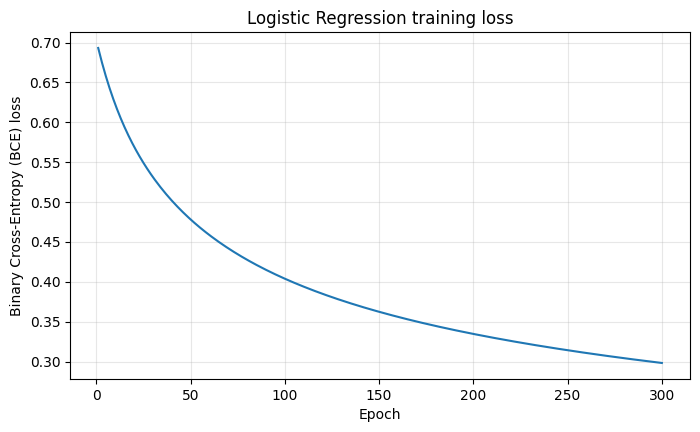

In [28]:

# FINAL EVALUATION ON UNSEEN TEST REVIEWS
# predict() uses the learned weights and sigmoid threshold.
# Accuracy measures the percentage of correct predictions.
# Precision measures how reliable positive predictions are.
# Recall measures how many actual positives are detected.
# F1 combines precision and recall into one score.

y_pred_lr = lr_model.predict(X_test_lr)
lr_accuracy = accuracy(y_test, y_pred_lr)
lr_f1, lr_precision, lr_recall = f1_score(y_test, y_pred_lr)

print('Logistic Regression — test results')
print(f'Accuracy:  {lr_accuracy:.4f} ({lr_accuracy * 100:.2f}%)')
print(f'F1-score:  {lr_f1:.4f}')
print(f'Precision: {lr_precision:.4f}')
print(f'Recall:    {lr_recall:.4f}')

# Confusion matrix for the final Logistic Regression model
tn = np.sum((y_test == 0) & (y_pred_lr == 0))
fp = np.sum((y_test == 0) & (y_pred_lr == 1))
fn = np.sum((y_test == 1) & (y_pred_lr == 0))
tp = np.sum((y_test == 1) & (y_pred_lr == 1))

print("Confusion matrix:")
print(np.array([[tn, fp], [fn, tp]]))

# Check that all 1,000 reviews were evaluated
assert tn + fp + fn + tp == len(y_test)

# LOSS CURVE
# loss_history contains one BCE value for each training epoch.
# X-axis = epoch number; Y-axis = training BCE loss.
# A decreasing curve means gradient descent is reducing training loss.
# Test accuracy and F1 are still needed to evaluate generalization.

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(lr_model.loss_history) + 1), lr_model.loss_history)
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy (BCE) loss')
plt.title('Logistic Regression training loss')
plt.grid(alpha=0.3)
plt.show()

# Part 4: Model comparison and analysis

We compare the three sentiment classifiers on the **same 1,000-review IMDB test set**.

| Model | Input representation | Classification method |
|---|---|---|
| Bigram Language Model | Word sequences / neighboring word pairs | Choose the class with lower perplexity |
| Naive Bayes | Counts of 2,000 unigrams and bigrams | Sum log-ratios and the class prior |
| Logistic Regression | Standardized NB-weighted feature counts | Sigmoid probability after learned linear weights |

The next cell prints the test accuracy and F1 of all three models from the variables computed above.


In [29]:
model_results = [
    ('Bigram LM', 'Bigram word sequences', lm_accuracy, lm_f1),
    ('Naive Bayes', 'Unigram/bigram counts', acc, f1),
    ('Logistic Regression', 'Standardized NB-weighted counts', lr_accuracy, lr_f1),
]

print(f"{'Model':<22} {'Input representation':<33} {'Accuracy':>9} {'F1':>9}")
print('-' * 80)
for name, representation, model_acc, model_f1 in model_results:
    print(f'{name:<22} {representation:<33} {model_acc:>9.4f} {model_f1:>9.4f}')

best_model = max(model_results, key=lambda row: row[3])
print(f'Highest test F1: {best_model[0]} ({best_model[3]:.4f})')

Model                  Input representation               Accuracy        F1
--------------------------------------------------------------------------------
Bigram LM              Bigram word sequences                0.8470    0.8428
Naive Bayes            Unigram/bigram counts                0.8030    0.7967
Logistic Regression    Standardized NB-weighted counts      0.8590    0.8627
Highest test F1: Logistic Regression (0.8627)


## 4.1 Analysis

### Results

All three models are evaluated on the same 1,000 test reviews (500 positive, 500 negative):

| Model | Input representation | Accuracy | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Bigram language model | Bigram word sequences | 84.70% | 0.8428 | 0.8668 | 0.8200 |
| Naive Bayes | Counts of 2,000 unigrams/bigrams | 80.30% | 0.7967 | 0.8230 | 0.7720 |
| **NB-weighted logistic regression** | Standardized NB-weighted counts | **85.90%** | **0.8627** | 0.8406 | **0.8860** |

### Bigram language model

The bigram LMs reach 84.70% accuracy (F1 0.8428) by asking which class's model finds a review less surprising. They use every word of the review, in order, over a vocabulary of 41,300 entries, so local phrases such as "waste of" or "the worst" count directly. Precision is higher than recall: the model labels 527 reviews negative and 473 positive, so it leans slightly towards negative. The perplexities themselves are very large (about 8,800 for the first test review) because Add-1 smoothing spreads probability over all 41,300 possible next words, but only the comparison between the two models matters.

### Naive Bayes

Naive Bayes is the weakest model, at 80.30% accuracy (F1 0.7967).

- **It is not overfitting:** training accuracy (81.28%) is close to test accuracy, so it is limited by its features, not by memorising the training data.
- **It sees only part of each review:** the 2,000 features are a small slice of the 482,780 distinct n-grams in the training set, and a review hits about 236 of them on average. The language model, in contrast, uses its whole vocabulary.
- **Overlapping features are double-counted:** the independence assumption treats "waste" and "waste of" as separate evidence, although one implies the other.
- **It leans negative:** 114 positive reviews are labelled negative, against 83 negative reviews labelled positive.
- **Some features reflect topic, not opinion:** "bond" (James Bond films) is among the most positive features and "zombies" among the most negative.

### NB-weighted logistic regression

Logistic regression is the best model, at 85.90% accuracy (F1 0.8627). It keeps the Naive Bayes log-ratios as feature weights, then *learns* how much to trust each feature by minimising binary cross-entropy, so it can correct the double-counting that hurts Naive Bayes. The learning rate (0.01) and number of epochs (300) were chosen on a held-out validation set of 500 training reviews (validation F1 0.8505), with the Naive Bayes ratios recomputed on the training fold so that validation labels never leak into the features. Training loss falls from 0.693 to 0.298 over the 300 epochs.

Unlike the other two models, its recall (0.886) is higher than its precision (0.841), so it leans slightly towards predicting positive.

### Generative vs. discriminative models

The bigram LM and Naive Bayes are **generative**: they model how each class produces text, $P(\text{document} \mid \text{class})$ or $P(\text{feature} \mid \text{class})$, and classify with Bayes' rule. Logistic regression is **discriminative**: it models $P(\text{class} \mid \text{features})$ directly and fits its weights to the classification objective. Together with the richer, standardized features, this difference in objective is a likely reason why logistic regression does best here.

### Conclusion

NB-weighted logistic regression is the best model in this experiment:

- **vs. the bigram LM:** +1.2 percentage points accuracy and +0.0199 F1 (0.8428 → 0.8627);
- **vs. Naive Bayes:** +5.6 percentage points accuracy and +0.0660 F1 (0.7967 → 0.8627).

The test set has 1,000 reviews, so one percentage point is only 10 reviews. The gap over Naive Bayes is large and clear; the gap over the bigram LM is small and should not be over-read.

### Possible improvements

- Train on the full 25,000-review training set instead of the 5,000-review subset.
- Select the 2,000 features inside each validation fold, so the vocabulary also never sees validation reviews.
- Use a stronger smoothing method for the language models (for example Kneser–Ney), and try a larger or tuned feature vocabulary for Naive Bayes and logistic regression.